# Module 9: Integrated Capital Allocation of ₹1,000 crore

**Board question:** Where should NovaFin deploy ₹1,000 crore of incremental capital, what risks will it take, and how should those risks be controlled?

This notebook pulls together the saved outputs of Modules 1–8 and turns them into one allocation.

**Method:**
1. Build an **evidence table**: for each business line, the expected annual return on capital (ROC), a severe-but-plausible stress loss, and capacity limits, each traced to a module.
2. Set **risk appetite constraints**: liquidity floor, concentration caps, a stress-loss budget, and a hedging rule.
3. **Optimise:** maximise expected return subject to those constraints (a small linear program).
4. Apply a **management overlay** and **stress-test** the final allocation.

**What you will learn:** risk-adjusted return on capital, capital budgeting under constraints, linear programming, and scenario analysis.

## 0. Setup
Run Modules 1–8 first: this notebook reads their files from the `outputs` folder.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, subprocess, importlib.util
if importlib.util.find_spec("google.colab"):             # Colab: install the extra libraries once
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap", "xgboost", "lightgbm", "imbalanced-learn"])
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.optimize import linprog
try:
    from google.colab import drive; drive.mount("/content/drive")
except ImportError:
    pass
CANDIDATES = [Path("/content/drive/MyDrive/NovaFin_Capstone/data"), Path("../../Project"), Path("/mnt/project-files/Project")]
DATA = next(p for p in CANDIDATES if (p / "nova_loans.csv").exists())
OUT = DATA.parent / "outputs" if "drive" in str(DATA) else Path("../outputs")
sns.set_theme(style="whitegrid", palette="deep")
BUDGET = 1000              # ₹ crore
RF = 0.065                 # risk-free / liquidity yield
CAPITAL_RATIO = 0.12       # equity capital held per ₹1 of loans (Basel-style assumption)
print(sorted(p.name for p in OUT.glob("*.csv")))

['m1_by_business_unit.csv', 'm1_initiatives.csv', 'm2_loan_decisions.csv', 'm2_segments.csv', 'm3_summary.csv', 'm3_test_alerts.csv', 'm4_customers_scored.csv', 'm4_summary.csv', 'm4_top1000_contact_list.csv', 'm5_model_evaluation.csv', 'm6_latest_weights.csv', 'm6_portfolio_performance.csv', 'm6_var.csv', 'm7_hft_summary.csv', 'm8_greeks_by_underlying.csv', 'm8_hedge.csv', 'm8_pricing_comparison.csv', 'm8_summary.csv', 'm9_controls.csv', 'm9_final_allocation.csv', 'm9_sensitivity.csv', 'm9_stress_test.csv']


## 1. Evidence from each module

### Module 1: strategic initiatives
The *Fund* list needs a fixed amount of capital. We convert each initiative's expected NPV into an **equivalent annual return**: discount rate + ENPV ÷ (investment × 5-year annuity factor). Money in the data is in ₹ lakh, so ÷100 gives ₹ crore.

In [2]:
m1 = pd.read_csv(OUT / "m1_initiatives.csv")
annuity = lambda r, n=5: (1 - (1 + r) ** -n) / r
m1["EAR"] = m1.Discount_Rate + m1.ENPV / (m1.Initial_Investment * annuity(m1.Discount_Rate))
fund, review = m1[m1.Decision == "Fund"], m1[m1.Decision == "Review"]
wavg = lambda g: (g.EAR * g.Initial_Investment).sum() / g.Initial_Investment.sum()
init_bu = fund.groupby("Business_Unit").apply(lambda g: pd.Series({"initiatives": len(g), "capital_cr": g.Initial_Investment.sum() / 100, "annual_return": wavg(g)})).round(3)
print(f"Fund list: {len(fund)} initiatives, ₹{fund.Initial_Investment.sum()/100:.1f} crore, return {wavg(fund):.1%}")
print(f"Review list: {len(review)} initiatives, ₹{review.Initial_Investment.sum()/100:.1f} crore, return {wavg(review):.1%} (before review)")
init_bu

Fund list: 45 initiatives, ₹67.3 crore, return 16.3%
Review list: 20 initiatives, ₹31.3 crore, return 17.7% (before review)


,initiatives,capital_cr,annual_return
Business_Unit,,,
Corporate Banking,3.0,5.013,0.160
Digital Banking,10.0,13.304,0.141
Payments,12.0,16.731,0.155
Risk Analytics,7.0,13.058,0.158
SME Lending,4.0,3.862,0.173
Wealth,9.0,15.333,0.195


### Module 2: lending
At **current** pricing the approved (Low/Medium PD) book barely earns its cost of funds. With **risk-based repricing** (every approved loan priced at least 1 point above its break-even rate), the risk-adjusted return on loans improves. Lending is leveraged: ₹1 of capital supports ₹1 ÷ 12% ≈ ₹8.3 of loans, so ROC = loan return ÷ 12%.

In [3]:
loans = pd.read_csv(OUT / "m2_loan_decisions.csv")
raw = pd.read_csv(DATA / "nova_loans.csv")[["Customer_ID", "Interest_Rate", "Loan_Term_Months"]]
a = loans.merge(raw, left_on="Loan_ID", right_on="Customer_ID").query("Decision == 'Approve'").copy()
a["BalYears"] = 0.55 * a.Loan_Term_Months / 12
a["Breakeven"] = 0.06 + a.ECL / (a.Loan_Amount * a.BalYears * (1 - a.Predicted_PD))
def loan_return(rate):
    profit = a.Loan_Amount * (rate - 0.06) * a.BalYears * (1 - a.Predicted_PD) - a.ECL
    return a.assign(p=profit).groupby("Customer_Type").apply(lambda g: g.p.sum() / (g.Loan_Amount * g.BalYears).sum())
lend = pd.DataFrame({"current pricing": loan_return(a.Interest_Rate / 100), "repriced (break-even + 1pt)": loan_return(np.maximum(a.Interest_Rate / 100, a.Breakeven + 0.01))})
lend["annual loss rate"] = a.groupby("Customer_Type").apply(lambda g: g.ECL.sum() / (g.Loan_Amount * g.BalYears).sum())
lend["ROC current"] = lend["current pricing"] / CAPITAL_RATIO
lend["ROC repriced"] = lend["repriced (break-even + 1pt)"] / CAPITAL_RATIO
lend.round(4)

,current pricing,repriced (break-even + 1pt),annual loss rate,ROC current,ROC repriced
Customer_Type,,,,,
Corporate,0.0018,0.0111,0.0182,0.0146,0.0928
Retail,0.0020,0.0112,0.0171,0.0169,0.0937


**Stress:** if PDs rise 50% (a recession), annual credit losses rise by half the loss rate; as a share of capital that is 0.5 × loss rate ÷ 12%.

In [4]:
lend["stress loss on capital"] = 0.5 * lend["annual loss rate"] / CAPITAL_RATIO + 0.03   # + 3% for margin squeeze / concentration
lend[["ROC repriced", "stress loss on capital"]].round(3)

,ROC repriced,stress loss on capital
Customer_Type,,
Corporate,0.093,0.106
Retail,0.094,0.101


### Module 3: fraud, Module 4: customers
These are not capital-hungry lines but **enablers**: the fraud model cuts fraud-related cost by about a third, and the retention list covers about 2.5× the value of a random list. We fund them as fixed programmes inside Digital banking and Wealth management.

In [5]:
m3 = pd.read_csv(OUT / "m3_summary.csv", index_col=0).squeeze()
m4 = pd.read_csv(OUT / "m4_summary.csv", index_col=0).squeeze()
print(f"Fraud: cost reduction {float(m3['cost_reduction_pct']):.0%}, recall {float(m3['recall']):.0%}, alerts on {float(m3['alerts_share']):.1%} of transactions")
print(f"Customers: churn model CV AUC {float(m4['cv_auc']):.2f}; top-1,000 list covers ₹{float(m4['top1000_clv_cr']):.1f} crore of CLV")

Fraud: cost reduction 35%, recall 47%, alerts on 7.0% of transactions
Customers: churn model CV AUC 0.50; top-1,000 list covers ₹24.7 crore of CLV


### Modules 5–6: equity, Module 7: HFT, Module 8: derivatives

In [6]:
perf = pd.read_csv(OUT / "m6_portfolio_performance.csv", index_col=0)
var = pd.read_csv(OUT / "m6_var.csv", index_col=0).squeeze()
m7 = pd.read_csv(OUT / "m7_hft_summary.csv", index_col=0).squeeze()
m8 = pd.read_csv(OUT / "m8_summary.csv", index_col=0).squeeze()
print(perf.round(3)); print(var)
print(f"HFT: accuracy {float(m7['accuracy']):.2f} vs baseline {float(m7['baseline_accuracy']):.2f}; net {float(m7['avg_net_bps']):.2f} bps/trade; edge gone at {m7['breakeven_cost_multiple']}× spread; est. ₹{float(m7['annual_pnl_inr'])/1e7:.2f} crore a year")
print(f"Options book: unhedged P&L on −10% = ₹{float(m8['unhedged_loss_10pct_down']):,.0f}; hedged = ₹{float(m8['hedged_loss_10pct_down']):,.0f}")

                 CAGR  Volatility  Sharpe  Max drawdown  Calmar  \
Equal weight    0.150       0.076   1.019        -0.045   3.360   
Markowitz       0.141       0.120   0.619        -0.137   1.033   
ML top-5        0.066       0.128   0.054        -0.158   0.417   
ML + Markowitz  0.099       0.117   0.312        -0.139   0.716   

                Avg monthly turnover  
Equal weight                   0.000  
Markowitz                      0.374  
ML top-5                       1.343  
ML + Markowitz                 1.253  
Historical VaR 99%        0.0113
Parametric VaR 99%        0.0106
Monte Carlo VaR 99%       0.0106
Expected shortfall 99%    0.0120
Name: 0, dtype: float64
HFT: accuracy 0.61 vs baseline 0.41; net 1.68 bps/trade; edge gone at 2.25× spread; est. ₹1.59 crore a year
Options book: unhedged P&L on −10% = ₹-90,621; hedged = ₹135,124


**Equity assumptions:** the equal-weight backtest earned ~15% a year with Sharpe ≈ 1, but over a short, calm sample. We haircut the expected return to 12% and use a 20% market crash as the stress, reduced to 12% when the book is hedged with index puts (Module 8 logic). The hedging rule is a budget of 5% of the equity allocation.

**HFT assumptions:** ~₹1.6 crore a year on ~₹20 crore of margin and technology ≈ 8% ROC, capacity-capped at ₹20 crore, 15% stress loss (model failure, a fast-market event).

## 2. Evidence table

In [7]:
lines = pd.DataFrame([
    # name, brief category, ROC, stress loss, min, max, source
    ["Strategic initiatives: Fund list", "Digital banking / Wealth / Lending (by BU)", wavg(fund), 0.25, fund.Initial_Investment.sum() / 100, fund.Initial_Investment.sum() / 100, "Module 1"],
    ["Strategic initiatives: Review list", "Contingent (by BU)", 0.6 * wavg(review), 0.40, 0, review.Initial_Investment.sum() / 200, "Module 1 (60% haircut for uncertainty)"],
    ["Retail & SME lending growth", "Retail lending", lend.loc["Retail", "ROC repriced"], lend.loc["Retail", "stress loss on capital"], 0, 300, "Module 2"],
    ["Corporate lending growth", "Corporate lending", lend.loc["Corporate", "ROC repriced"], lend.loc["Corporate", "stress loss on capital"] + 0.01, 0, 300, "Module 2 (+1pt concentration)"],
    ["Equity portfolio (equal-weight core)", "Equity investments", 0.12, 0.12, 0, 250, "Modules 5-6"],
    ["Derivatives hedging budget", "Derivatives hedging", 0.0, 0.0, 0, 1000, "Module 8"],
    ["HFT / execution desk", "High frequency trading", 0.08, 0.15, 0, 20, "Module 7"],
    ["Fraud & retention analytics programme", "Digital banking / Wealth", 0.10, 0.05, 10, 10, "Modules 3-4 (fixed programme)"],
    ["Liquidity reserve", "Liquidity reserve", RF, 0.0, 100, 1000, "Policy floor 10%"],
], columns=["Line", "Brief category", "ROC", "Stress loss", "Min ₹cr", "Max ₹cr", "Evidence"])
lines.round(3)

,Line,Brief category,ROC,Stress loss,Min ₹cr,Max ₹cr,Evidence
0,Strategic initiatives: Fund list,Digital banking / Wealth / Lending (by BU),0.163,0.250,67.301,67.301,Module 1
1,Strategic initiatives: Review list,Contingent (by BU),0.106,0.400,0.000,15.626,Module 1 (60% haircut for uncertainty)
2,Retail & SME lending growth,Retail lending,0.094,0.101,0.000,300.000,Module 2
3,Corporate lending growth,Corporate lending,0.093,0.116,0.000,300.000,Module 2 (+1pt concentration)
4,Equity portfolio (equal-weight core),Equity investments,0.120,0.120,0.000,250.000,Modules 5-6
5,Derivatives hedging budget,Derivatives hedging,0.000,0.000,0.000,1000.000,Module 8
6,HFT / execution desk,High frequency trading,0.080,0.150,0.000,20.000,Module 7
7,Fraud & retention analytics programme,Digital banking / Wealth,0.100,0.050,10.000,10.000,Modules 3-4 (fixed programme)
8,Liquidity reserve,Liquidity reserve,0.065,0.000,100.000,1000.000,Policy floor 10%


## 3. Risk appetite and the optimiser
Constraints (all are our assumptions, set as a board would):
1. Total = ₹1,000 crore.
2. Liquidity reserve ≥ 10%; no line above 30%; equity ≤ 25%; HFT ≤ ₹20 crore (capacity).
3. **Stress-loss budget:** in a severe year, total stress loss ≤ 8% of the ₹1,000 crore (₹80 crore).
4. **Hedging rule:** hedging budget ≥ 5% of the equity allocation.

Objective: maximise expected annual return = Σ ROC × allocation.

In [8]:
def optimise(tbl, stress_budget=0.08):
    n = len(tbl)
    hedge_row = np.zeros(n); hedge_row[tbl.index[tbl.Line.str.startswith("Equity")][0]] = 0.05; hedge_row[tbl.index[tbl.Line.str.startswith("Derivatives")][0]] = -1
    res = linprog(-tbl.ROC.values, A_ub=[tbl["Stress loss"].values, hedge_row], b_ub=[stress_budget * BUDGET, 0],
                  A_eq=[np.ones(n)], b_eq=[BUDGET], bounds=list(zip(tbl["Min ₹cr"], tbl["Max ₹cr"])), method="highs")
    return pd.Series(res.x, index=tbl.Line).round(1)
opt = optimise(lines)
opt.to_frame("₹ crore")

,₹ crore
Line,
Strategic initiatives: Fund list,67.3
Strategic initiatives: Review list,0.0
Retail & SME lending growth,300.0
Corporate lending growth,20.2
Equity portfolio (equal-weight core),250.0
Derivatives hedging budget,12.5
HFT / execution desk,0.0
Fraud & retention analytics programme,10.0
Liquidity reserve,340.0


### Sensitivity: how does the answer change with the assumptions?

In [9]:
not_repriced = lines.copy()
not_repriced.loc[not_repriced.Line.str.startswith("Retail"), "ROC"] = lend.loc["Retail", "ROC current"]
not_repriced.loc[not_repriced.Line.str.startswith("Corporate"), "ROC"] = lend.loc["Corporate", "ROC current"]
sens = pd.DataFrame({"Base (8% stress budget)": opt,
                     "Tighter appetite (6%)": optimise(lines, 0.06),
                     "Looser appetite (10%)": optimise(lines, 0.10),
                     "Lending NOT repriced": optimise(not_repriced)})
sens

,Base (8% stress budget),Tighter appetite (6%),Looser appetite (10%),Lending NOT repriced
Line,,,,
Strategic initiatives: Fund list,67.3,67.3,67.3,67.3
Strategic initiatives: Review list,0.0,0.0,0.0,15.6
Retail & SME lending growth,300.0,125.3,300.0,0.0
Corporate lending growth,20.2,0.0,193.1,0.0
Equity portfolio (equal-weight core),250.0,250.0,250.0,250.0
Derivatives hedging budget,12.5,12.5,12.5,12.5
HFT / execution desk,0.0,0.0,0.0,20.0
Fraud & retention analytics programme,10.0,10.0,10.0,10.0
Liquidity reserve,340.0,534.9,167.1,624.6


**Key sensitivity:** if loans are *not* repriced, the optimiser moves almost all lending capital into the liquidity reserve, because current pricing does not cover expected losses. **Repricing is a precondition for lending growth.**

## 4. Management overlay and final allocation
The optimiser is a guide, not the decision. Overlay (management judgement):
- Fund an **HFT/execution pilot of ₹10 crore**: the signal is real (Module 7), and improving NovaFin's own execution has value the ROC does not capture. Taken from the liquidity reserve.
- **Hold the Review-list contingency (≈ ₹15 crore) inside the liquidity reserve** until due diligence clears individual initiatives.
- Re-run the optimiser with these two lines fixed so everything else adjusts and the stress budget still holds, then round.

In [10]:
overlay = lines.copy()
overlay.loc[overlay.Line.str.startswith("HFT"), ["Min ₹cr", "Max ₹cr"]] = 10          # fixed ₹10 crore pilot
overlay.loc[overlay.Line.str.contains("Review"), ["Min ₹cr", "Max ₹cr"]] = 0          # contingency held in the reserve
final = optimise(overlay).round(0)                                                   # re-optimise so the stress budget still holds
final["Liquidity reserve"] += BUDGET - final.sum()
alloc = lines.set_index("Line").assign(Allocation=final)[["Brief category", "Allocation", "ROC", "Stress loss", "Evidence"]]
alloc["Share"] = alloc.Allocation / BUDGET
alloc["Exp. return ₹cr"] = alloc.Allocation * alloc.ROC
alloc["Stress loss ₹cr"] = alloc.Allocation * alloc["Stress loss"]
alloc = alloc[alloc.Allocation > 0]
alloc.round(3)

,Brief category,Allocation,ROC,Stress loss,Evidence,Share,Exp. return ₹cr,Stress loss ₹cr
Line,,,,,,,,
Strategic initiatives: Fund list,Digital banking / Wealth / Lending (by BU),67.0,0.163,0.250,Module 1,0.067,10.940,16.750
Retail & SME lending growth,Retail lending,300.0,0.094,0.101,Module 2,0.300,28.108,30.341
Corporate lending growth,Corporate lending,7.0,0.093,0.116,Module 2 (+1pt concentration),0.007,0.650,0.810
Equity portfolio (equal-weight core),Equity investments,250.0,0.120,0.120,Modules 5-6,0.250,30.000,30.000
Derivatives hedging budget,Derivatives hedging,12.0,0.000,0.000,Module 8,0.012,0.000,0.000
HFT / execution desk,High frequency trading,10.0,0.080,0.150,Module 7,0.010,0.800,1.500
Fraud & retention analytics programme,Digital banking / Wealth,10.0,0.100,0.050,Modules 3-4 (fixed programme),0.010,1.000,0.500
Liquidity reserve,Liquidity reserve,344.0,0.065,0.000,Policy floor 10%,0.344,22.360,0.000


In [11]:
tot = alloc[["Allocation", "Exp. return ₹cr", "Stress loss ₹cr"]].sum()
print(f"Total allocated: ₹{tot.Allocation:,.0f} crore")
print(f"Expected annual return: ₹{tot['Exp. return ₹cr']:.1f} crore = {tot['Exp. return ₹cr']/BUDGET:.1%} on capital")
print(f"Severe-year stress loss: ₹{tot['Stress loss ₹cr']:.1f} crore = {tot['Stress loss ₹cr']/BUDGET:.1%} (budget 8%)")

Total allocated: ₹1,000 crore
Expected annual return: ₹93.9 crore = 9.4% on capital
Severe-year stress loss: ₹79.9 crore = 8.0% (budget 8%)


In [12]:
init_split = (init_bu.capital_cr / init_bu.capital_cr.sum() * alloc.loc["Strategic initiatives: Fund list", "Allocation"]).round(1)
print("Fund-list capital by business unit (₹ crore):"); print(init_split)

Fund-list capital by business unit (₹ crore):
Business_Unit
Corporate Banking     5.0
Digital Banking      13.2
Payments             16.7
Risk Analytics       13.0
SME Lending           3.8
Wealth               15.3
Name: capital_cr, dtype: float64


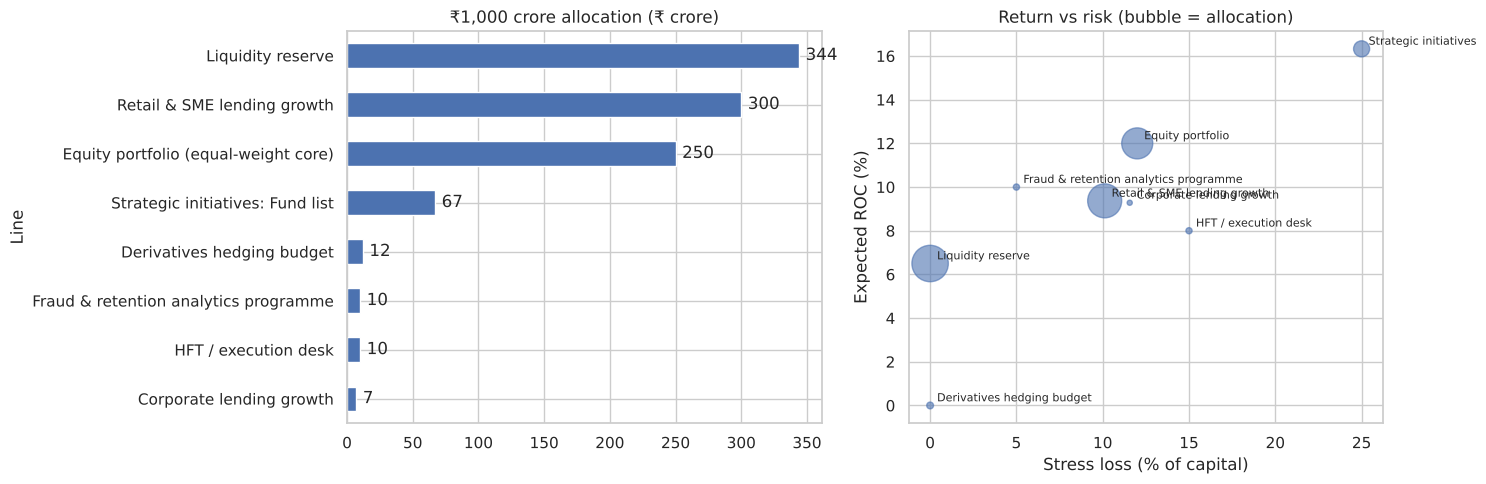

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
alloc.Allocation.sort_values().plot.barh(ax=ax[0], color="C0", title="₹1,000 crore allocation (₹ crore)")
for i, v in enumerate(alloc.Allocation.sort_values()): ax[0].text(v + 5, i, f"{v:.0f}", va="center")
ax[1].scatter(alloc["Stress loss"] * 100, alloc.ROC * 100, s=alloc.Allocation * 2, alpha=0.6)
for name, r in alloc.iterrows(): ax[1].annotate(name.split(" (")[0].split(":")[0], (r["Stress loss"] * 100, r.ROC * 100), fontsize=8, xytext=(5, 3), textcoords="offset points")
ax[1].set(xlabel="Stress loss (% of capital)", ylabel="Expected ROC (%)", title="Return vs risk (bubble = allocation)")
plt.tight_layout(); plt.show()

## 5. Stress-testing the final allocation
Scenarios:
1. **Credit downturn:** PDs +50%.
2. **Equity crash:** −20% market (hedged equity loses 12%; HFT model fails).
3. **Combined severe year:** both, plus initiative failures.

In [14]:
def scen(credit=False, equity=False, initiatives=False):
    loss = 0
    for name, r in alloc.iterrows():
        if credit and "lending" in name: loss += r.Allocation * r["Stress loss"]
        if equity and ("Equity" in name or "HFT" in name): loss += r.Allocation * r["Stress loss"]
        if initiatives and "initiatives" in name: loss += r.Allocation * r["Stress loss"]
    return loss
st = pd.DataFrame({"Loss ₹cr": [scen(credit=True), scen(equity=True), scen(True, True, True)]},
                  index=["Credit downturn", "Equity crash", "Combined severe year"])
st["Loss % of capital"] = st["Loss ₹cr"] / BUDGET
st["Net of expected return ₹cr"] = tot["Exp. return ₹cr"] - st["Loss ₹cr"]
st["Liquidity reserve covers loss?"] = alloc.loc["Liquidity reserve", "Allocation"] > st["Loss ₹cr"]
st.round(3)

,Loss ₹cr,Loss % of capital,Net of expected return ₹cr,Liquidity reserve covers loss?
Credit downturn,31.15,0.031,62.708,True
Equity crash,31.50,0.032,62.358,True
Combined severe year,79.40,0.079,14.458,True


Even in the combined severe year, losses stay within the 8% appetite and are covered several times over by the liquidity reserve.

## 6. Risks and controls by line

In [15]:
controls = pd.DataFrame([
    ["Retail & SME / Corporate lending", "Credit risk; PD model drift", "PD model (Module 2), risk-based pricing", "Approve only PD < 15%; reprice to break-even + 1pt; single-name and sector limits", "PD calibration vs actual defaults quarterly; ECL vs provisions"],
    ["Strategic initiatives", "Execution risk; weak success model", "NPV/ENPV (Module 1)", "Stage-gated funding; Review list only after due diligence", "Milestone tracking; post-investment review"],
    ["Equity portfolio", "Market risk", "Equal-weight core (Module 6), VaR", "≤ 25% of capital; 1-day 99% VaR limit; drawdown stop at −10%", "Daily VaR and backtest exceptions"],
    ["Derivatives hedging", "Delta, vega, gamma risk", "Black-Scholes Greeks (Module 8)", "Daily delta rebalancing; vega and gamma limits; hedge ≥ 5% of equity", "Greeks report; hedge effectiveness"],
    ["HFT / execution", "Model and operational risk", "LightGBM direction model (Module 7)", "₹10 crore cap; daily loss limit; kill-switch", "Hit rate, net bps per trade, cost drift"],
    ["Fraud & retention analytics", "False alerts; customer friction", "Fraud model + cost threshold (Module 3), CLV list (Module 4)", "Threshold re-tuned monthly; A/B test the retention campaign", "Fraud catch rate, alert precision, retention uplift"],
    ["Liquidity reserve", "Opportunity cost", "Policy", "≥ 10% of capital; high-quality liquid assets only", "Coverage of stress losses"],
], columns=["Line", "Main risk", "Model / evidence", "Control / limit", "Monitoring KPI"])
controls

,Line,Main risk,Model / evidence,Control / limit,Monitoring KPI
0,Retail & SME / Corporate lending,Credit risk; PD model drift,"PD model (Module 2), risk-based pricing",Approve only PD < 15%; reprice to break-even +...,PD calibration vs actual defaults quarterly; E...
1,Strategic initiatives,Execution risk; weak success model,NPV/ENPV (Module 1),Stage-gated funding; Review list only after du...,Milestone tracking; post-investment review
2,Equity portfolio,Market risk,"Equal-weight core (Module 6), VaR",≤ 25% of capital; 1-day 99% VaR limit; drawdow...,Daily VaR and backtest exceptions
3,Derivatives hedging,"Delta, vega, gamma risk",Black-Scholes Greeks (Module 8),Daily delta rebalancing; vega and gamma limits...,Greeks report; hedge effectiveness
4,HFT / execution,Model and operational risk,LightGBM direction model (Module 7),₹10 crore cap; daily loss limit; kill-switch,"Hit rate, net bps per trade, cost drift"
5,Fraud & retention analytics,False alerts; customer friction,"Fraud model + cost threshold (Module 3), CLV l...",Threshold re-tuned monthly; A/B test the reten...,"Fraud catch rate, alert precision, retention u..."
6,Liquidity reserve,Opportunity cost,Policy,≥ 10% of capital; high-quality liquid assets only,Coverage of stress losses


## 7. Save outputs

In [16]:
alloc.round(4).to_csv(OUT / "m9_final_allocation.csv")
st.round(4).to_csv(OUT / "m9_stress_test.csv")
sens.to_csv(OUT / "m9_sensitivity.csv")
controls.to_csv(OUT / "m9_controls.csv", index=False)
print("Saved")

Saved


## 8. Board recommendation
1. **Fund the strategic initiatives on the Fund list in full** (≈ ₹67 crore across Wealth, Payments, Risk Analytics, Digital Banking, Corporate Banking and SME Lending); keep the Review list as a contingency inside the reserve.
2. **Grow lending only with risk-based repricing**, mainly retail and SME, approving PD < 15% borrowers. Without repricing, lending destroys value at today's rates.
3. **Run the equity book as a diversified, low-turnover core** with a hedging budget, not an ML stock-picking strategy (ML did not beat equal weight).
4. **Pilot HFT/execution** with a small, capped allocation: the signal is real but thin.
5. **Fund fraud and retention analytics** as enablers, and keep a **large liquidity reserve**, which the stress-loss budget requires.
6. Every line has a model, a limit and a KPI (table above). Models are reviewed under a model-governance framework: validation before use, monitoring, annual recalibration and human sign-off.